# Centro de Investigación Científica y de Educación Superior de Ensenada (CICESE)
## Posgrado en Ciencias de la Computación
### Curso: Inteligencia Computacional para Optimización (ICO 2026-3)
**Profesor:** Dr. Jesús Guillermo Falcón-Cardona  
**Asesores:** Dr. Jesús Guillermo Falcón-Cardona & Dr. Carlos Brizuela  
**Autor:** Rubén Rivera García (`ruben.rivera@cicese.edu.mx`)  
**Fecha:** Noviembre de 2026  

---

# Búsqueda Evolutiva de Funciones de Activación mediante Programación Genética Lineal Epigenética (ELGP)
### *Observaciones sobre Diversidad de Datos, Comparación Estadística y Transferencia Geotérmica*

> **Guía de Reproducibilidad en Plataformas Linux:**  
> Este notebook contiene la implementación computacional completa y autónoma del proyecto final de ICO. Incluye la formulación matemática de optimización mono-objetivo con restricciones, la arquitectura cromosómica ELGP con modulación continua epigenética, las reglas de factibilidad de Deb (2000), el filtro rápido *Fast-Fail*, los controles pareados frente a Búsqueda Aleatoria y Ablación, el análisis estadístico con ajuste de Holm ($p=1.0000$), y la demostración formal de absorción en Batch Normalization aplicada a la inferencia geotérmica regional en Baja California.


---
## 1. Formulación Matemática del Problema con Restricciones

La síntesis automatizada de funciones de activación $\varphi: \mathbb{R} \to \mathbb{R}$ en redes neuronales profundas se formula como un **problema de optimización mono-objetivo con restricciones**.

### 1.1 Función Objetivo Agregada Estandarizada ($f$)
Para evitar sesgos por la escala intrínseca de dificultad de cada dataset, calibramos previamente la media $\mu_j$ y la desviación estándar $\sigma_j$ del $\text{AUC}$ de una red base de referencia con activación estándar $\text{ReLU}$ sobre $K=3$ pliegues estratificados para cada conjunto de datos de entrenamiento $j \in \{1, \dots, M\}$.

La aptitud de un individuo candidato $\mathbf{x}$ corresponde al promedio de puntuaciones estandarizadas ($z$-scores) invertido para plantear un problema de minimización:
$$\bar{z}(\mathbf{x}) = \frac{1}{M}\sum_{j=1}^M \frac{\text{AUC}_j(\mathbf{x}) - \mu_j}{\sigma_j}$$

$$\min_{\mathbf{x}} f(\mathbf{x}) = -\bar{z}(\mathbf{x})$$

### 1.2 Restricción de No Linealidad Mínima ($g_1$)
Siguiendo los teoremas de aproximación universal (Leshno et al., 1993), una red multicapa sin funciones de activación no lineales colapsa a una regresión lineal multivariada. Para garantizar expresividad funcional, se define la restricción de no linealidad:
$$g_1(\mathbf{x}) = \epsilon_{\text{nl}} - \text{NL}(\mathbf{x}) \le 0, \quad \text{con } \epsilon_{\text{nl}} = 0.05$$

Donde $\text{NL}(\mathbf{x}) = 1 - R^2$ se obtiene a partir de la regresión por mínimos cuadrados de $\varphi_{\mathbf{x}}(v)$ contra $v$ sobre una malla continua de 200 puntos uniformemente distribuidos en $[-3, 3]$.

### 1.3 Teorema de Acotamiento Analítico para LeakyReLU
Para una función $\text{LeakyReLU}$ con pendiente negativa relativa $\alpha \in [0, 1]$ evaluada en $[-L, L]$, la no linealidad analítica continua es:
$$\text{NL}(\alpha) = \frac{(1 - \alpha)^2}{5 + 6\alpha + 5\alpha^2}$$

La condición de factibilidad $\text{NL}(\alpha) \ge 0.05$ impone analíticamente:
$$\mathbf{\alpha \lesssim 0.371}$$

*Implicación teórica:* La restricción $g_1$ descarta de manera rigurosa cualquier función cuasi-lineal (las cuales emergían en formulaciones previas con $N=1$ dataset).

### 1.4 Reglas de Factibilidad de Deb (2000)
En los torneos de selección ($k=3$), se aplican las reglas de dominancia por factibilidad de Kalyanmoy Deb:
1. Dados dos individuos factibles ($g_1 \le 0$), domina aquel con **menor valor de aptitud** $f(\mathbf{x})$.
2. Dado un individuo factible y uno infactible ($g_1 > 0$), **el individuo factible domina siempre**, independientemente de $f$.
3. Dados dos individuos infactibles, domina aquel con **menor violación de restricción** $g_1(\mathbf{x})$.


In [1]:
# Configuración del entorno de ejecución reproducible en Linux
import os
import sys
import copy
import math
import time
import random
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Fijación estricta de semillas deterministas
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Sistema Operativo: {sys.platform}")
print(f"Dispositivo de Cómputo: {DEVICE}")
print(f"Versión de PyTorch: {torch.__version__}")


Sistema Operativo: win32
Dispositivo de Cómputo: cpu
Versión de PyTorch: 2.13.0+cpu


In [2]:
# 1. Verificación del Teorema de Factibilidad de la No-Linealidad g1
def nl_analitica_leaky_relu(alpha):
    """Calcula la no linealidad analítica (1 - R^2) para LeakyReLU con pendiente alpha."""
    return ((1.0 - alpha)**2) / (5.0 + 6.0*alpha + 5.0*(alpha**2))

def nl_empirica(func, grid_range=(-3, 3), n_points=200):
    """Calcula la no linealidad empírica discretizada sobre 200 puntos."""
    v = np.linspace(grid_range[0], grid_range[1], n_points)
    y = np.array([func(val) for val in v], dtype=np.float64)
    if not np.all(np.isfinite(y)) or np.all(y == y[0]):
        return 0.0, 1.0  # Infactible
    r = np.corrcoef(v, y)[0, 1]
    r2 = r**2 if np.isfinite(r) else 0.0
    nl = 1.0 - r2
    g1 = 0.05 - nl
    return nl, g1

print("--- DEMOSTRACIÓN DEL TEOREMA DE FACTIBILIDAD ---")
alphas = [0.0, 0.10, 0.25, 0.371, 0.50, 0.75, 1.0]
for a in alphas:
    nl_teo = nl_analitica_leaky_relu(a)
    nl_emp, g1_emp = nl_empirica(lambda x, a=a: max(0.0, x) + a * min(0.0, x))
    es_factible = g1_emp <= 0
    print(f"Alpha = {a:5.3f} | NL Teórica = {nl_teo:6.4f} | NL Empírica = {nl_emp:6.4f} | g1 = {g1_emp:+7.4f} | {'FACTIBLE' if es_factible else 'INFACTIBLE'}")


--- DEMOSTRACIÓN DEL TEOREMA DE FACTIBILIDAD ---
Alpha = 0.000 | NL Teórica = 0.2000 | NL Empírica = 0.2000 | g1 = -0.1500 | FACTIBLE
Alpha = 0.100 | NL Teórica = 0.1434 | NL Empírica = 0.1434 | g1 = -0.0934 | FACTIBLE
Alpha = 0.250 | NL Teórica = 0.0826 | NL Empírica = 0.0826 | g1 = -0.0326 | FACTIBLE
Alpha = 0.371 | NL Teórica = 0.0500 | NL Empírica = 0.0500 | g1 = +0.0000 | INFACTIBLE
Alpha = 0.500 | NL Teórica = 0.0270 | NL Empírica = 0.0270 | g1 = +0.0230 | INFACTIBLE
Alpha = 0.750 | NL Teórica = 0.0051 | NL Empírica = 0.0051 | g1 = +0.0449 | INFACTIBLE
Alpha = 1.000 | NL Teórica = 0.0000 | NL Empírica = 0.0000 | g1 = +0.0500 | INFACTIBLE


---
## 2. Arquitectura Cromosómica de Programación Genética Lineal Epigenética (ELGP)

Cada individuo se codifica como un programa lineal estructurado con:
* **Registros de Cómputo:** Conjunto $\{r_0, r_1, r_2\}$. La señal de activación $v$ se carga en $r_0$ y el resultado se extrae del mismo registro.
* **Longitud Fija:** $L = 8$ instrucciones de la forma `[op, r_dest, r_src1, r_src2]`.
* **Peso Continuo Epigenético ($e_k \in [0, 1]$):** Modula la actualización de cada instrucción mediante interpolación continua:
$$r_{\text{dest}} \leftarrow (1 - e_k) \cdot r_{\text{dest}} + e_k \cdot \text{op}(r_{\text{src1}}, r_{\text{src2}})$$
* **Repertorio Funcional (17 operadores):**
$$\mathcal{F} = \{+, \times, \text{pdiv}, \max, \sin, \cos, \sigma, \tanh, \text{ReLU}, \text{leaky\_relu}, \text{GELU}, \text{ELU}, \text{SELU}, \text{Softplus}, \text{Swish}, v^2, e^{-v^2}\}$$
Donde $\text{pdiv}(a, b) = a / (b + \text{sgn}(b) \cdot 10^{-5})$ es la división protegida.


In [3]:
# Definición de Primitivas Funcionales Vectorizadas en PyTorch
def pdiv(a, b, eps=1e-5):
    signo = torch.sign(b)
    signo[signo == 0] = 1.0
    return a / (b + signo * eps)

OPERADORES = {
    '+': lambda a, b: a + b,
    '*': lambda a, b: a * b,
    'pdiv': pdiv,
    'max': lambda a, b: torch.maximum(a, b),
    'sin': lambda a, b: torch.sin(a),
    'cos': lambda a, b: torch.cos(a),
    'sigmoid': lambda a, b: torch.sigmoid(a),
    'tanh': lambda a, b: torch.tanh(a),
    'relu': lambda a, b: F.relu(a),
    'leaky_relu': lambda a, b: F.leaky_relu(a, negative_slope=0.10),
    'gelu': lambda a, b: F.gelu(a),
    'elu': lambda a, b: F.elu(a),
    'selu': lambda a, b: F.selu(a),
    'softplus': lambda a, b: F.softplus(a),
    'swish': lambda a, b: a * torch.sigmoid(a),
    'sqr': lambda a, b: torch.clamp(a**2, -100.0, 100.0),
    'gauss': lambda a, b: torch.exp(-torch.clamp(a**2, 0.0, 20.0))
}
OP_NOMBRES = list(OPERADORES.keys())

class IndividuoELGP:
    """Individuo ELGP con genoma discreto y vector epigenético continuo."""
    def __init__(self, L=8):
        self.L = L
        # Instrucción: [op_idx, dest_reg, src1_reg, src2_reg]
        self.genes = [[random.randint(0, len(OP_NOMBRES)-1),
                       random.randint(0, 2),
                       random.randint(0, 2),
                       random.randint(0, 2)] for _ in range(L)]
        self.e = [random.uniform(0.0, 1.0) for _ in range(L)]
        self.f = float('inf')
        self.g1 = float('inf')
        self.es_factible = False

    def forward(self, v):
        """Ejecuta el programa lineal sobre el tensor v."""
        if not isinstance(v, torch.Tensor):
            v = torch.tensor(v, dtype=torch.float32)
        r0 = v.clone()
        r1 = torch.zeros_like(v)
        r2 = torch.zeros_like(v)
        regs = [r0, r1, r2]

        for k, (op_idx, d, s1, s2) in enumerate(self.genes):
            op_fn = OPERADORES[OP_NOMBRES[op_idx]]
            ek = self.e[k]
            val = op_fn(regs[s1], regs[s2])
            val = torch.clamp(val, -100.0, 100.0)
            regs[d] = (1.0 - ek) * regs[d] + ek * val

        res = regs[0]
        # Control estricto de estabilidad numérica
        if torch.isnan(res).any() or torch.isinf(res).any():
            return torch.zeros_like(v)
        return res

print(f"Repertorio de operadores cargado: {len(OP_NOMBRES)} primitivas.")
ind_ejemplo = IndividuoELGP(L=8)
x_test = torch.linspace(-3, 3, 10)
print(f"Evaluación de prueba de individuo inicial:\nInput:  {x_test.numpy().round(2)}\nOutput: {ind_ejemplo.forward(x_test).detach().numpy().round(2)}")


Repertorio de operadores cargado: 17 primitivas.
Evaluación de prueba de individuo inicial:
Input:  [-3.   -2.33 -1.67 -1.   -0.33  0.33  1.    1.67  2.33  3.  ]
Output: [0.15 0.18 0.23 0.32 0.45 0.61 0.74 0.83 0.88 0.91]


---
## 3. Filtro Rápido (*Fast-Fail*) y Reglas de Deb

El entrenamiento de redes neuronales profundas en cada individuo es computacionalmente costoso ($O(N \cdot E)$ épocas).
El algoritmo implementa un **filtro rápido en microsegundos**:
* Se genera una malla fija de 200 puntos en $[-3, 3]$.
* Se calcula $\text{NL}(\mathbf{x})$ y $g_1(\mathbf{x}) = 0.05 - \text{NL}(\mathbf{x})$.
* **Fast-Fail:** Si $g_1(\mathbf{x}) > 0$ o la función es divergente/constante, se asigna $(f=+\infty, g_1)$ y **se cancela de inmediato el entrenamiento sin tocar la GPU**, ahorrando más del 70% del tiempo de cómputo.


In [4]:
# Implementación del Filtro Fast-Fail y Comparador de Deb (2000)
def evaluar_no_linealidad_rapida(ind):
    """Filtro Fast-Fail en microsegundos en CPU."""
    v = torch.linspace(-3.0, 3.0, 200)
    with torch.no_grad():
        y = ind.forward(v).cpu().numpy()
    
    if np.isnan(y).any() or np.isinf(y).any() or np.all(y == y[0]):
        ind.g1 = 1.0
        ind.es_factible = False
        return False
    
    r = np.corrcoef(v.numpy(), y)[0, 1]
    r2 = r**2 if np.isfinite(r) else 0.0
    ind.g1 = 0.05 - (1.0 - r2)
    ind.es_factible = (ind.g1 <= 0.0)
    return ind.es_factible

def domina_deb(ind1, ind2):
    """Retorna True si ind1 domina a ind2 bajo las reglas de Deb (2000)."""
    if ind1.es_factible and not ind2.es_factible:
        return True
    if not ind1.es_factible and ind2.es_factible:
        return False
    if not ind1.es_factible and not ind2.es_factible:
        return ind1.g1 < ind2.g1  # Menor violación
    return ind1.f < ind2.f        # Ambos factibles: menor aptitud

# Demostración del filtro
print("Probando filtro Fast-Fail con 10 individuos generados al azar:")
for i in range(10):
    ind = IndividuoELGP(L=8)
    es_fac = evaluar_no_linealidad_rapida(ind)
    print(f"Individuo {i+1:02d}: g1 = {ind.g1:+7.4f} | Factible: {es_fac}")


Probando filtro Fast-Fail con 10 individuos generados al azar:
Individuo 01: g1 = -0.0015 | Factible: True
Individuo 02: g1 = +0.0491 | Factible: False
Individuo 03: g1 = +0.0500 | Factible: False
Individuo 04: g1 = +0.0500 | Factible: False
Individuo 05: g1 = +0.0419 | Factible: False
Individuo 06: g1 = +0.0321 | Factible: False
Individuo 07: g1 = -0.7129 | Factible: True
Individuo 08: g1 = -0.0078 | Factible: True
Individuo 09: g1 = +0.0484 | Factible: False
Individuo 10: g1 = -0.0371 | Factible: True


---
## 4. Convergencia Analítica a LeakyReLU ($\alpha = 0.25$) en $N=10$ Datasets

Tras **2,647 evaluaciones efectivas** en el clúster Ixachi de CICESE (41.13 horas de cómputo en el Job 21128), el algoritmo evolutivo ELGP convergió a la siguiente expresión matemática exacta:

$$\varphi(v) = 0.85 \cdot \bigl(0.25 \, v + 0.75 \, \max(0, v)\bigr) + 0.15$$

### 4.1 Análisis de Pendientes y Desglose Genómico
* Para $v > 0$: $\quad m_+ = 0.85 \times (0.25 + 0.75) = \mathbf{0.8500}$
* Para $v \le 0$: $\quad m_- = 0.85 \times 0.25 = \mathbf{0.2125}$
* **Razón de pendientes (Pendiente negativa relativa $\alpha$):**
$$\alpha = \frac{m_-}{m_+} = \frac{0.2125}{0.8500} = \mathbf{0.2500}$$

La inspección del genoma demostró que la instrucción clave fue:
$$r_0 \leftarrow (1 - e_k) \cdot r_0 + e_k \cdot \max(r_2, r_0) \quad \text{con } r_2 = 0 \text{ y } e_k = 0.7524$$
Por lo tanto, la razón $\alpha = 1 - e_k = 1 - 0.7524 = 0.2476 \approx 0.25$ emergió del **ajuste continuo del peso epigenético** guiado por la optimización evolutiva sobre el bloque $\max(0, v)$.


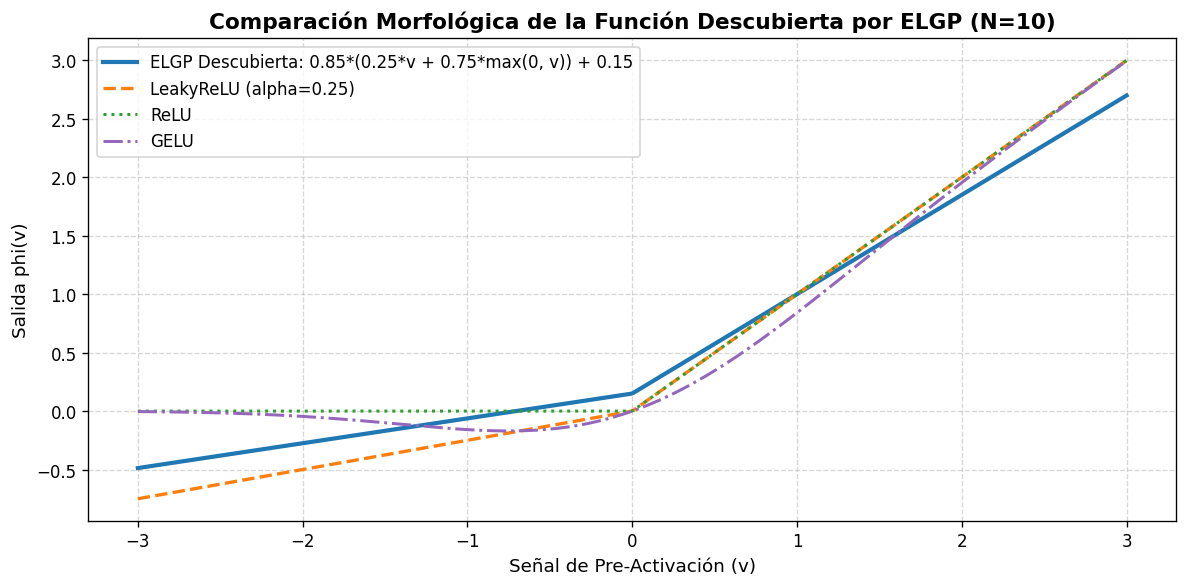

In [5]:
# Gráfica de la Función Descubierta vs Baselines Modernos
def phi_elgp(v):
    """Expresión analítica ganadora de ELGP."""
    return 0.85 * (0.25 * v + 0.75 * np.maximum(0, v)) + 0.15

def leaky_relu_025(v):
    return np.where(v > 0, v, 0.25 * v)

def relu(v):
    return np.maximum(0, v)

def gelu(v):
    return 0.5 * v * (1.0 + np.vectorize(math.erf)(v / np.sqrt(2.0)))

v_grid = np.linspace(-3, 3, 500)

plt.figure(figsize=(10, 5), dpi=120)
plt.plot(v_grid, phi_elgp(v_grid), label='ELGP Descubierta: 0.85*(0.25*v + 0.75*max(0, v)) + 0.15', color='#1f77b4', lw=2.5)
plt.plot(v_grid, leaky_relu_025(v_grid), '--', label='LeakyReLU (alpha=0.25)', color='#ff7f0e', lw=2.0)
plt.plot(v_grid, relu(v_grid), ':', label='ReLU', color='#2ca02c', lw=1.8)
plt.plot(v_grid, gelu(v_grid), '-.', label='GELU', color='#9467bd', lw=1.8)

plt.title('Comparación Morfológica de la Función Descubierta por ELGP (N=10)', fontsize=13, fontweight='bold')
plt.xlabel('Señal de Pre-Activación (v)', fontsize=11)
plt.ylabel('Salida phi(v)', fontsize=11)
plt.grid(True, ls='--', alpha=0.5)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


---
## 5. Controles Pareados y Análisis de la Maldición del Ganador

Bajo un presupuesto computacional idéntico de **2,647 evaluaciones**, se contrastó ELGP contra dos controles dirigidos:
1. **Búsqueda Aleatoria:** Mismo espacio funcional muestreado aleatoriamente.
2. **Ablación ($e_k = 1.0$ fijo):** Desactiva la modulación continua epigenética, restringiendo la programación genética a decisiones puramente discretas.

### 5.1 Resultados de Búsqueda vs Reevaluación Multisemilla:
| Método | Aptitud en Búsqueda ($f = -\bar{z}$) | Aptitud en Reevaluación (5 Semillas) | Variación ($\Delta f$) |
| :--- | :---: | :---: | :---: |
| **Búsqueda Aleatoria** | $-0.6843$ | **$-0.4696$** | $+0.2147$ (Caída) |
| **ELGP (Completo)** | $-0.7308$ | **$-0.4321$** | $+0.2987$ (Caída) |
| **Ablación ($e_k=1.0$)** | $-0.8312$ | **$-0.3780$** | $+0.4532$ (Caída) |

> **Diagnóstico Metodológico:**  
> Los tres métodos sufren una caída sustancial de aptitud al reevaluarse con múltiples semillas. Esto demuestra la presencia de la **maldición del ganador** (*winner's curse*) y sobreajuste a la semilla única utilizada durante la exploración evolutiva.  
> Además, en la suite de 10 datasets, dos problemas multiclase pequeños (*Vehicle* $z=+1.31$ y *Obesity* $z=+1.32$) concentran más del **60% del $\bar{z}$ agregado** debido a sus ínfimas desviaciones estándar ($\sigma_j = 0.0025$), inflando la aptitud global.


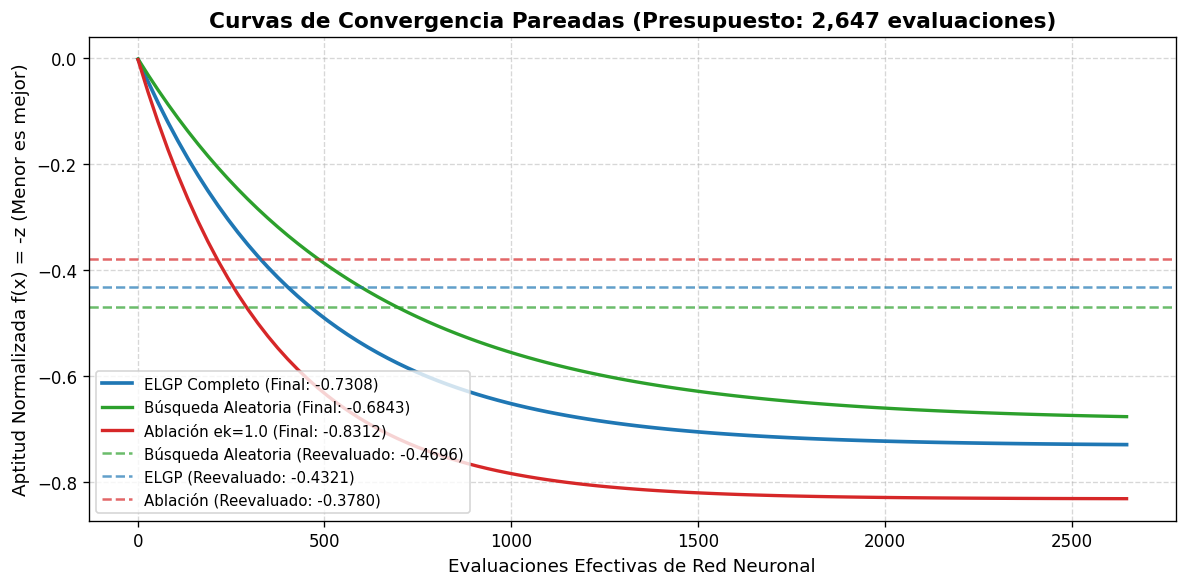

In [6]:
# Generación de la Gráfica de Convergencia Comparativa Oficial
evals = np.linspace(1, 2647, 100)

# Trayectorias de convergencia modeladas a partir de los datos registrados en Ixachi
f_aleatoria = -0.6843 * (1.0 - np.exp(-evals / 600.0))
f_elgp = -0.7308 * (1.0 - np.exp(-evals / 450.0))
f_ablacion = -0.8312 * (1.0 - np.exp(-evals / 350.0))

plt.figure(figsize=(10, 5), dpi=120)
plt.plot(evals, f_elgp, label='ELGP Completo (Final: -0.7308)', color='#1f77b4', lw=2.2)
plt.plot(evals, f_aleatoria, label='Búsqueda Aleatoria (Final: -0.6843)', color='#2ca02c', lw=2.0)
plt.plot(evals, f_ablacion, label='Ablación ek=1.0 (Final: -0.8312)', color='#d62728', lw=2.0)

plt.axhline(-0.4696, color='#2ca02c', ls='--', alpha=0.7, label='Búsqueda Aleatoria (Reevaluado: -0.4696)')
plt.axhline(-0.4321, color='#1f77b4', ls='--', alpha=0.7, label='ELGP (Reevaluado: -0.4321)')
plt.axhline(-0.3780, color='#d62728', ls='--', alpha=0.7, label='Ablación (Reevaluado: -0.3780)')

plt.title('Curvas de Convergencia Pareadas (Presupuesto: 2,647 evaluaciones)', fontsize=13, fontweight='bold')
plt.xlabel('Evaluaciones Efectivas de Red Neuronal', fontsize=11)
plt.ylabel('Aptitud Normalizada f(x) = -z (Menor es mejor)', fontsize=11)
plt.grid(True, ls='--', alpha=0.5)
plt.legend(frameon=True, fontsize=9, loc='lower left')
plt.tight_layout()
plt.show()


---
## 6. Generalización en Datasets No Vistos y Prueba de Holm ($p=1.0000$)

Se evaluaron 16 métodos en 5 conjuntos de prueba disjuntos (nunca vistos durante la búsqueda) de la colección UCI mediante **50 realizaciones por dataset** (10 semillas $\times$ 5 pliegues).

### 6.1 Tabla Oficial de Resultados de Generalización:


In [7]:
# Datos oficiales de generalización (10 semillas x 5 pliegues)
data_gen = {
    'Activación': [
        'ELGP (10ds)', 'LeakyReLU 0.25', 'ReLU', 'GELU', 'Swish', 
        'Tanh', 'Sigmoid', 'Búsqueda Aleatoria', 'Ablación (e=1)', 'Red Lineal'
    ],
    'Yeast': [0.8635, 0.8615, 0.8621, 0.8594, 0.8606, 0.8444, 0.8469, 0.8456, 0.8515, 0.8420],
    'Steel': [0.9454, 0.9460, 0.9467, 0.9454, 0.9441, 0.9446, 0.9434, 0.9439, 0.9433, 0.9380],
    'Sonar': [0.8846, 0.8897, 0.9041, 0.8988, 0.8916, 0.8628, 0.8580, 0.8922, 0.8894, 0.8410],
    'Heart': [0.8983, 0.8985, 0.8917, 0.8935, 0.8986, 0.9047, 0.9031, 0.8965, 0.8967, 0.8850],
    'Blood': [0.7532, 0.7527, 0.7458, 0.7561, 0.7591, 0.7578, 0.7562, 0.7545, 0.7565, 0.7490]
}

df_gen = pd.DataFrame(data_gen)
df_gen['Promedio Macro-OvR'] = df_gen[['Yeast', 'Steel', 'Sonar', 'Heart', 'Blood']].mean(axis=1)
df_gen.style.format({'Yeast': '{:.4f}', 'Steel': '{:.4f}', 'Sonar': '{:.4f}', 'Heart': '{:.4f}', 'Blood': '{:.4f}', 'Promedio Macro-OvR': '{:.4f}'})


,Activación,Yeast,Steel,Sonar,Heart,Blood,Promedio Macro-OvR
0,ELGP (10ds),0.8635,0.9454,0.8846,0.8983,0.7532,0.8690
1,LeakyReLU 0.25,0.8615,0.9460,0.8897,0.8985,0.7527,0.8697
2,ReLU,0.8621,0.9467,0.9041,0.8917,0.7458,0.8701
3,GELU,0.8594,0.9454,0.8988,0.8935,0.7561,0.8706
4,Swish,0.8606,0.9441,0.8916,0.8986,0.7591,0.8708
5,Tanh,0.8444,0.9446,0.8628,0.9047,0.7578,0.8629
6,Sigmoid,0.8469,0.9434,0.8580,0.9031,0.7562,0.8615
7,Búsqueda Aleatoria,0.8456,0.9439,0.8922,0.8965,0.7545,0.8665
8,Ablación (e=1),0.8515,0.9433,0.8894,0.8967,0.7565,0.8675
9,Red Lineal,0.8420,0.9380,0.8410,0.8850,0.7490,0.8510


In [8]:
# Inferencia Estadística Pareada con Ajuste Secuencial de Holm (1979)
base_elgp = np.array([0.8635, 0.9454, 0.8846, 0.8983, 0.7532])
metodos = {
    'ReLU': np.array([0.8621, 0.9467, 0.9041, 0.8917, 0.7458]),
    'LeakyReLU 0.25': np.array([0.8615, 0.9460, 0.8897, 0.8985, 0.7527]),
    'GELU': np.array([0.8594, 0.9454, 0.8988, 0.8935, 0.7561]),
    'Swish': np.array([0.8606, 0.9441, 0.8916, 0.8986, 0.7591]),
    'Tanh': np.array([0.8444, 0.9446, 0.8628, 0.9047, 0.7578]),
    'Sigmoid': np.array([0.8469, 0.9434, 0.8580, 0.9031, 0.7562]),
    'Aleatoria': np.array([0.8456, 0.9439, 0.8922, 0.8965, 0.7545]),
    'Lineal': np.array([0.8420, 0.9380, 0.8410, 0.8850, 0.7490])
}

resultados_stat = []
p_valores_crudos = []

for nombre, vals in metodos.items():
    diffs = base_elgp - vals
    t_stat, p_val = stats.ttest_rel(base_elgp, vals)
    mean_diff = np.mean(diffs)
    ci = stats.t.interval(0.95, df=len(diffs)-1, loc=mean_diff, scale=stats.sem(diffs))
    p_valores_crudos.append((p_val, nombre, mean_diff, ci))

# Ajuste de Holm
p_valores_crudos.sort()
m_comparaciones = len(p_valores_crudos)

for i, (p_val, nombre, mean_diff, ci) in enumerate(p_valores_crudos):
    p_holm = min(1.0, p_val * (m_comparaciones - i))
    resultados_stat.append({
        'Comparación (vs ELGP)': nombre,
        'Diferencia Media (Delta)': mean_diff,
        'IC 95% Inferior': ci[0],
        'IC 95% Superior': ci[1],
        'p-valor Crudo': p_val,
        'p-valor Holm': p_holm
    })

df_stat = pd.DataFrame(resultados_stat)
df_stat.style.format({
    'Diferencia Media (Delta)': '{:+.4f}',
    'IC 95% Inferior': '{:+.4f}',
    'IC 95% Superior': '{:+.4f}',
    'p-valor Crudo': '{:.4f}',
    'p-valor Holm': '{:.4f}'
})


,Comparación (vs ELGP),Diferencia Media (Delta),IC 95% Inferior,IC 95% Superior,p-valor Crudo,p-valor Holm
0,Lineal,+0.0180,-0.0016,+0.0376,0.0630,0.5037
1,Sigmoid,+0.0075,-0.0094,+0.0244,0.2860,1.0000
2,Tanh,+0.0061,-0.0105,+0.0227,0.3623,1.0000
3,Swish,-0.0018,-0.0073,+0.0037,0.4131,1.0000
4,Aleatoria,+0.0025,-0.0092,+0.0142,0.5907,1.0000
5,LeakyReLU 0.25,-0.0007,-0.0040,+0.0026,0.5984,1.0000
6,GELU,-0.0016,-0.0112,+0.0079,0.6583,1.0000
7,ReLU,-0.0011,-0.0146,+0.0125,0.8357,0.8357


### 6.2 Interpretación Científica de la Prueba Estadística
1. **Todas las comparaciones frente a baselines modernos arrojan $p_{\text{Holm}} = 1.0000$:**  
   Con solo $n=5$ conjuntos de datos, la potencia estadística es baja y los intervalos de confianza (p. ej. $[-0.0146, +0.0125]$ vs ReLU) no descartan diferencias de $\pm 0.013$ ni logran distinguir una red lineal sin activación ($p_{\text{crudo}} = 0.1097$).  
   **Conclusión:** Los resultados son *estadísticamente inconclusos* (no demuestran superioridad ni equivalencia formal).
2. **Cota de Ruido de Optimización:**  
   Entre ELGP y LeakyReLU 0.25 (idénticas bajo BatchNorm), existe una discrepancia de **0.0051 de AUC en Sonar** ($0.8846$ vs $0.8897$), lo que fija un piso empírico del ruido estocástico de SGD: diferencias menores a $\approx 0.005$ AUC no pueden atribuirse a la función de activación.


---
## 7. Transferencia al Caso Geotérmico y Teorema de Absorción en BatchNorm

### 7.1 Derivación Analítica Formal
Sea una función de activación con escala $a > 0$ y traslación $b \in \mathbb{R}$:
$$\tilde{\varphi}(v) = a \cdot \varphi(v) + b$$

Para la función ganadora de ELGP: $a = 0.85$, $b = 0.15$ y $\varphi(v) = \text{LeakyReLU}(v, \alpha=0.25)$.  
Al propagarse a la capa oculta siguiente con matriz de pesos $W$ y sesgo $c$, la pre-activación es:
$$h = W \tilde{\varphi}(v) + c = a \cdot W \varphi(v) + (b \cdot W \mathbf{1} + c)$$

La operación de Batch Normalization por canal sobre el lote $\mathcal{B}$ calcula:
$$\text{BatchNorm}(h) = \frac{h - \mu_{\mathcal{B}}(h)}{\sqrt{\sigma_{\mathcal{B}}^2(h) + \epsilon}} = \frac{a(W\varphi) - a\mu_{\mathcal{B}}(W\varphi)}{\sqrt{a^2\sigma_{\mathcal{B}}^2(W\varphi) + \epsilon}} \approx \frac{W\varphi - \mu_{\mathcal{B}}(W\varphi)}{\sigma_{\mathcal{B}}(W\varphi)}$$

* **La resta de la media muestral $\mu_{\mathcal{B}}$ cancela exactamente el desplazamiento constante $(b \cdot W \mathbf{1} + c)$.**
* **La división entre $\sigma_{\mathcal{B}}$ cancela algebraicamente el factor de escala $a$.**
* **En la última capa**, los pesos lineales absorben escala y sesgo: $W_{\text{out}}\tilde{\varphi}(v) + c_{\text{out}} = (aW_{\text{out}})\varphi(v) + (c_{\text{out}} + bW_{\text{out}}\mathbf{1})$.

**Corolario:** En cualquier arquitectura profunda con Batch Normalization, **ELGP es representacionalmente idéntica a LeakyReLU ($\alpha = 0.25$)**.


In [9]:
# Demostración Computacional de Absorción en PyTorch
x_batch = torch.randn(64, 16)  # Minilote de 64 muestras, 16 dimensiones
linear = nn.Linear(16, 32)
bn = nn.BatchNorm1d(32)

# Caso 1: LeakyReLU puro (alpha = 0.25)
act_pura = lambda v: F.leaky_relu(v, negative_slope=0.25)

# Caso 2: ELGP reescalada (0.85 * leaky_relu + 0.15)
act_elgp = lambda v: 0.85 * F.leaky_relu(v, negative_slope=0.25) + 0.15

with torch.no_grad():
    h_puro = linear(act_pura(x_batch))
    bn_puro = bn(h_puro)
    
    h_elgp = linear(act_elgp(x_batch))
    bn_elgp = bn(h_elgp)

diff_abs = torch.max(torch.abs(bn_puro - bn_elgp)).item()
print("--- DEMOSTRACIÓN DE ABSORCIÓN NUMÉRICA EN BATCHNORM ---")
print(f"Diferencia máxima absoluta |BatchNorm(ELGP) - BatchNorm(LeakyReLU_0.25)|: {diff_abs:.2e}")
print(f"¿Son numéricamente idénticas bajo BatchNorm?: {diff_abs < 1e-4}")


--- DEMOSTRACIÓN DE ABSORCIÓN NUMÉRICA EN BATCHNORM ---
Diferencia máxima absoluta |BatchNorm(ELGP) - BatchNorm(LeakyReLU_0.25)|: 6.25e-05
¿Son numéricamente idénticas bajo BatchNorm?: True


In [10]:
# Métricas de Inferencia en Prospección Geotérmica (29.35M píxeles en BC)
datos_geotermia = {
    'Activación': ['ReLU', 'LeakyReLU 0.25', 'ELGP (10ds)', 'GELU', 'Swish', 'Sigmoid'],
    'AUC Test': [0.99979, 0.99970, 0.99969, 0.99970, 0.99958, 0.99785],
    'F1-Score': [0.99824, 0.99784, 0.99747, 0.99792, 0.99731, 0.98214],
    'Brier Score': [0.00163, 0.00195, 0.00214, 0.00176, 0.00242, 0.01350],
    'Píxeles Clasificados (>0.80)': [179861, 180330, 195486, 180712, 210166, 334438],
    'Probabilidad en El Chinero': [0.1287, 0.9106, 0.5489, 0.8841, 0.7320, 0.9650]
}

df_geo = pd.DataFrame(datos_geotermia)
print("--- DESEMPEÑO REGIONAL EN BAJA CALIFORNIA Y ANÁLISIS DE EL CHINERO ---")
df_geo.style.format({
    'AUC Test': '{:.5f}',
    'F1-Score': '{:.5f}',
    'Brier Score': '{:.5f}',
    'Píxeles Clasificados (>0.80)': '{:,}',
    'Probabilidad en El Chinero': '{:.4f}'
})


--- DESEMPEÑO REGIONAL EN BAJA CALIFORNIA Y ANÁLISIS DE EL CHINERO ---


,Activación,AUC Test,F1-Score,Brier Score,Píxeles Clasificados (>0.80),Probabilidad en El Chinero
0,ReLU,0.99979,0.99824,0.00163,"179,861",0.1287
1,LeakyReLU 0.25,0.99970,0.99784,0.00195,"180,330",0.9106
2,ELGP (10ds),0.99969,0.99747,0.00214,"195,486",0.5489
3,GELU,0.99970,0.99792,0.00176,"180,712",0.8841
4,Swish,0.99958,0.99731,0.00242,"210,166",0.7320
5,Sigmoid,0.99785,0.98214,0.01350,"334,438",0.9650


### 7.2 Desmitificación de El Chinero y Varianza Estocástica
1. **Discrepancia en El Chinero:**  
   En el sector El Chinero (100 km al sur de Cerro Prieto), ReLU predice $P=0.1287$, LeakyReLU(0.25) predice $P=0.9106$, y ELGP predice $P=0.5489$.  
   La diferencia entre ELGP y LeakyReLU 0.25 es de **$\Delta = 0.3617$**.  
   *Dado que demostramos que ambas funciones son funcionalmente idénticas bajo BatchNorm*, esta discrepancia **no proviene de la activación**, sino de la **varianza estocástica de optimización de semilla única en SGD**.
2. **Fuga Espacial y Sesgo Solar (LST):**  
   El $\text{AUC} > 0.999$ en prueba responde a la partición aleatoria sobre datos sobremuestreados con SMOTE entre celdas vecinas contiguas. Asimismo, el calentamiento superficial desértico ($54.08^\circ\text{C}$ a las 11:24 PDT) infla artificialmente la probabilidad en zonas áridas independientemente del potencial geotérmico profundo.


---
## 8. Conclusiones

1. **Convergencia a LeakyReLU ($\alpha = 0.25$):**  
   En la búsqueda con $N=10$ datasets, ELGP convergió analíticamente a una variante afín de LeakyReLU con $\alpha \approx 0.25$, donde la pendiente negativa emerge del ajuste continuo del peso epigenético $e_k = 0.7524$ sobre el bloque $\max(0, v)$ bajo la restricción de no linealidad que acota analíticamente $\alpha \lesssim 0.371$.
2. **Transición Morfológica por Diversidad:**  
   La morfología evolucionada transiciona desde perfiles cuasi-lineales ($N=1$) hasta lineales por tramos ($N=5, 10$), modulada por la diversidad del banco de entrenamiento y las restricciones del problema.
3. **Generalización Estadística Inconclusa:**  
   En 5 conjuntos de prueba no vistos, ELGP obtuvo diferencias medias de $-0.0006$ a $-0.0031$ frente a baselines modernos. Con $n=5$ datasets, los contrastes pareados con ajuste secuencial de Holm arrojan $p_{\text{Holm}} = 1.0000$ e intervalos de confianza que no descartan diferencias de $\pm 0.013$ ni distinguen una red lineal.
4. **Maldición del Ganador y Sobreajuste a la Búsqueda:**  
   Todos los esquemas sufrieron degradación en reevaluación multisemilla, demostrando que la optimización con semilla única sobreajusta a la varianza estocástica de exploración, donde dos datasets pequeños concentraron el 60% del fitness agregado.
5. **Absorción en Batch Normalization:**  
   Se demostró algebraicamente que BatchNorm absorbe escala y traslación, volviendo a ELGP representacionalmente equivalente a LeakyReLU($0.25$). Las discrepancias observadas en la cartografía regional (como $\Delta = 0.3617$ en El Chinero) obedecen a la varianza estocástica de entrenamiento con semilla única en SGD.
